---
title: "Practice Activity 10-2: Penalized regression"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    html-math-method: mathml
    code-overflow: wrap
---

## Penalized Regression: Ridge and LASSO

So far we have approached feature selection---that is, selection of which ${\bf X}$ variables to based our predictions on---by considering several subsets of features and comparing scores. But what if we want to consider *all* of the features? We don't necessarily want to select all the features to include in our model, because we run the risk of overfitting to the training data. But maybe we want to *consider* every feature for selection rather than just a few subsets. Penalized regression is one way of performing de facto feature selection: throw all the available features into the model and let the model fitting sort out which to include.

In [55]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score

We'll use the Ames housing data. We'll do a little cleaning first to:

- Drop a few columns that have mostly missing values
- Drop a few rows with missing values
- Drop the ID columns (row order and PID)

In [56]:
ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")

# Get rid of columns with mostly NaN values
good_cols = ames.isna().sum() < 100
ames = ames.loc[:,good_cols]

# Drop other NAs
ames = ames.dropna()

# drop ID columns and put target in y
X = ames.drop(["SalePrice", "Order", "PID"], axis = 1)
y = ames["SalePrice"]

X

,MS SubClass,MS Zoning,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,20,RL,31770,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,62,0,0,0,0,0,5,2010,WD,Normal
1,20,RH,11622,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,0,0,0,120,0,0,6,2010,WD,Normal
2,20,RL,14267,Pave,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,36,0,0,0,0,12500,6,2010,WD,Normal
3,20,RL,11160,Pave,Reg,Lvl,AllPub,Corner,Gtl,NAmes,...,0,0,0,0,0,0,4,2010,WD,Normal
4,60,RL,13830,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,...,34,0,0,0,0,0,3,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,80,RL,7937,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Mitchel,...,0,0,0,0,0,0,3,2006,WD,Normal
2926,20,RL,8885,Pave,IR1,Low,AllPub,Inside,Mod,Mitchel,...,0,0,0,0,0,0,6,2006,WD,Normal
2927,85,RL,10441,Pave,Reg,Lvl,AllPub,Inside,Gtl,Mitchel,...,32,0,0,0,0,700,7,2006,WD,Normal
2928,20,RL,10010,Pave,Reg,Lvl,AllPub,Inside,Mod,Mitchel,...,38,0,0,0,0,0,4,2006,WD,Normal


In [57]:
y

0       215000
1       105000
2       172000
3       244000
4       189900
         ...  
2925    142500
2926    131000
2927    132000
2928    170000
2929    188000
Name: SalePrice, Length: 2821, dtype: int64

Let's try a linear regression model first. We'll standardize numerical predictors and dummify categorical predictors.

In [58]:
ct = ColumnTransformer(
  [
    ("dummify",
    OneHotEncoder(sparse_output = False, handle_unknown='ignore'),
    make_column_selector(dtype_include=object)),
    ("standardize",
    StandardScaler(),
    make_column_selector(dtype_include=np.number))
  ],
  remainder = "passthrough"
).set_output(transform="pandas")

In [59]:
lr_pipeline = Pipeline(
  [("preprocessing", ct),
  ("linear_regression", LinearRegression())]
)

In [60]:
lr_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

Now let's use cross-validation to evaluate based on $R^2$.

In [61]:
cross_val_score(lr_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88433686, 0.90316706, 0.87507511, 0.91216037, 0.82269502,
       0.73890838, 0.86879893, 0.63798647, 0.90277443, 0.90350125])

Hmmm... linear regression on all the predictors does not seem as bad as the textbook suggests, though there is considerably variability between the scores based on the different folds.

Let's add second degree polynomial terms for all numerical predictors and see what happens.

In [62]:
numeric_poly = Pipeline([
    ("polynomial_features", PolynomialFeatures(degree=2)),
    ("standardize", StandardScaler())
])

ct_poly = ColumnTransformer(
    [
        ("dummify",
         OneHotEncoder(sparse_output=False, handle_unknown="ignore"),
         make_column_selector(dtype_include=object)),

        ("numeric_poly",
         numeric_poly,
         make_column_selector(dtype_include=np.number))
    ],
    remainder="drop"
).set_output(transform="pandas")

In [63]:
poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("linear_regression", LinearRegression())]
)

In [64]:
poly_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the

In [65]:
cross_val_score(poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([  0.88322049,  -0.2351045 ,  -5.18937934,   0.23576715,
       -25.57248876,   0.65934136,   0.23955858,  -1.0532801 ,
        -3.71975499, -51.70824887])

OK, now that's bad. The moral is that just throwing in all the predictors might fit the training data well but can be pretty terrible when it comes to making predictions for new observations. We want to be more selective without having to laboriously search through many possible subsets of predictors. With 67 predictors there are $2^{67}\approx 10^{20}$ possible subsets---even before we consider polynomial terms, interactions, transformations, etc---so it would be impossible to fit every possible subset.

Instead, we include all predictors but "penalize" variables that don't contribute much to the model. Before getting to the penalty we'll consider some motivating conceptual questions.

1. Consider a simple linear regression of sale price on a single variable like living area. What is the process by which the coefficient for living area is determined? How does "least squares" work? **DISCUSS**

**Answer:** Least squares chooses the intercept and the living-area coefficient together to minimize the sum of squared differences between actual and predicted sale prices in the training data. It finds the line with the smallest total squared prediction error.

2. Now consider a multiple of regression on living area and number of bedrooms, without standardizing variables. How does least squares work in this case? **DISCUSS**

**Answer:** Least squares chooses the intercept and both coefficients together to minimize the sum of squared prediction errors in the training data. Each predicted sale price is the intercept plus the living-area coefficient times living area plus the bedroom coefficient times the number of bedrooms. The predictors remain in their original units.

3. If you fit the linear model, without standarizing variables, how do you interpret the coefficients for living area and number of bedrooms? What is their rough order of magnitude? Can we determine directly from the coefficients which variable the predicted prices are more sensitive to? **DISCUSS**

In [66]:
area_bedroom_lr = LinearRegression()
area_bedroom_lr.fit(X[["Gr Liv Area", "Bedroom AbvGr"]], y)

pd.Series(
    area_bedroom_lr.coef_,
    index=["Gr Liv Area", "Bedroom AbvGr"],
    name="Coefficient"
)

Gr Liv Area        136.185660
Bedroom AbvGr   -29132.499347
Name: Coefficient, dtype: float64

**Answer:** Holding the number of bedrooms constant, one additional square foot of living area increases the predicted sale price by about 136.19 dollars. Holding living area constant, one additional above-ground bedroom decreases the predicted price by about 29132.50 dollars. The coefficients are on the order of hundreds and tens of thousands, respectively. Their absolute sizes cannot directly show which predictor has a stronger effect over a comparable change because the predictors use different units. These are predictive associations, not causal effects.

4. If you standardize the variables first, how would you interpret the model coefficients? How could you determine, roughly, which variable the predicted prices are more sensitive to? **DISCUSS**

In [67]:
area_bedroom_scaled_lr = Pipeline([
    ("standardize", StandardScaler()),
    ("linear_regression", LinearRegression())
])

area_bedroom_scaled_lr.fit(X[["Gr Liv Area", "Bedroom AbvGr"]], y)

pd.Series(
    area_bedroom_scaled_lr.named_steps["linear_regression"].coef_,
    index=["Gr Liv Area", "Bedroom AbvGr"],
    name="Standardized predictor coefficient"
)

Gr Liv Area      68746.023895
Bedroom AbvGr   -23786.885009
Name: Standardized predictor coefficient, dtype: float64

**Answer:** After standardizing the predictors, each coefficient is the change in predicted sale price for a one-standard-deviation increase in that predictor, holding the other predictor constant. The changes are about 68746.02 dollars for living area and -23786.89 dollars for the number of above-ground bedrooms. Since living area has the larger absolute coefficient, predictions are more sensitive to a one-standard-deviation change in living area in this model. This comparison describes predictive sensitivity, not causal importance.

5. If we want to make the predictions *less* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

**Answer:** We should shrink the coefficient toward zero, reducing its absolute value. This makes the predicted response change less for a one-standard-deviation increase in that predictor, holding the other predictors constant.

6. If we want to make the predictions *not at all* sensitive to a particular standardized variable, what in principle should we do to its coefficient? **DISCUSS**

**Answer:** We should set the coefficient exactly equal to zero. Then changing that predictor alone will not change the model’s prediction, holding the other predictors constant.

7. Why does including a penalty like in ridge regression or LASSO "shrink" coefficients towards 0? **DISCUSS**

**Answer:** Ridge and LASSO minimize the sum of squared training errors plus a penalty on coefficient size. Moving coefficients toward zero reduces the penalty, so the fitted model balances fitting the training data against keeping coefficients small. Ridge uses squared coefficients, while LASSO uses their absolute values.

8. Why is it important to standarize variables when using a penalty? **DISCUSS**

**Answer:** Coefficient sizes depend on the units and scales of the predictors. Without standardization, changing a predictor’s units could change its penalty even though it contains the same information. Standardizing puts numerical predictors on a comparable scale so the penalty is applied more fairly.

9. What happens if the penalty parameter $\lambda$ is 0? **DISCUSS**

**Answer:** When lambda is zero, the penalty disappears. The model minimizes only the sum of squared training errors, so it becomes ordinary least squares linear regression with the same predictors.

10. What happens as the penalty parameter $\lambda$ gets larger and larger? **DISCUSS**

**Answer:** As lambda increases, the penalty becomes stronger and the coefficients are pushed toward zero. With a very large penalty, predictions approach the training mean of the response because the unpenalized intercept remains. Too much shrinkage can cause underfitting. LASSO can make coefficients exactly zero, while ridge generally approaches zero without reaching it.

11. Why do we not penalize the intercept? **DISCUSS**

**Answer:** The intercept sets the overall baseline prediction rather than the influence of a predictor. Penalizing it would unnecessarily pull this baseline toward zero, even when zero is not a meaningful response level. Leaving it unpenalized allows the model to match the overall level of the training data while shrinking the predictor coefficients

12. Assume $\lambda = 1$. Suppose a standardized predictor has a small coefficient, say $\beta = 0.1$. How much does that coefficient add to the LASSO penalty versus the ridge penalty? If the coefficient were reduced from 0.1 to 0, how much would each penalty decrease? Which penalty offers a larger payoff for eliminating a small coefficient entirely? **DISCUSS**

**Answer:** With lambda equal to 1 and a coefficient of 0.1, the LASSO penalty contribution is |0.1| = 0.1, while the ridge penalty contribution is 0.1² = 0.01. Reducing the coefficient to zero decreases the penalties by 0.1 and 0.01, respectively. For this small coefficient and the same lambda, LASSO offers a larger reduction in the penalty for eliminating the coefficient entirely.

- Ridge regression shrinks all coefficient estimates toward zero but typically keeps every predictor in the model.
- LASSO regression shrinks coefficients and can set some exactly to zero, automatically removing those predictors.
- Choose ridge when predictors are highly correlated and you think many of them contain useful predictive information. Ridge tends to share influence among correlated variables.
- Choose LASSO when you want a simpler, more interpretable model with automatic variable selection.
- With highly correlated predictors, LASSO may keep one and drop the others—sometimes somewhat arbitrarily—while ridge usually retains all of them with smaller coefficients.
- Both methods are useful when there are many predictors or when ordinary least squares may overfit.

**Note that in scikit-learn the penalty parameter $\lambda$ is called `alpha`.**

## Ridge Regression

Let's fit regression regression first.

In [68]:
ridge_pipeline = Pipeline(
  [("preprocessing", ct),
  ("ridge_regression", Ridge(alpha=1))]
)

In [69]:
ridge_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('ridge_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output o

In [70]:
cross_val_score(ridge_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88714414, 0.90234101, 0.87838221, 0.92163172, 0.8345624 ,
       0.74313152, 0.86135562, 0.68453605, 0.91776347, 0.90466508])

There are a lot of predictors so there are a lot of coefficients. The code below is just an illustration of how the coefficients in the ridge regression model compare to the original linear regression model.

In [71]:
coef_compare = pd.DataFrame()
coef_compare["feature"] = lr_pipeline.named_steps["preprocessing"].get_feature_names_out()

coef_compare["lr"] = lr_pipeline.named_steps['linear_regression'].coef_
coef_compare["ridge"] = ridge_pipeline.named_steps['ridge_regression'].coef_
coef_compare["diff"] = abs(coef_compare["lr"]) - abs(coef_compare["ridge"])

In [72]:
coef_compare.sort_values(by = "diff", ascending=False)

,feature,lr,ridge,diff
91,dummify__Roof Matl_ClyTile,-559653.342134,-233156.089658,326497.252476
93,dummify__Roof Matl_Membran,119504.966230,32582.552859,86922.413371
94,dummify__Roof Matl_Metal,109059.255835,28387.663156,80671.592679
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126
...,...,...,...,...
9,dummify__Lot Shape_IR2,3714.571039,7298.885203,-3584.314165
45,dummify__Neighborhood_NoRidge,23073.438286,27838.034970,-4764.596685
46,dummify__Neighborhood_NridgHt,17323.198503,22416.699195,-5093.500692
111,dummify__Exterior 1st_Stucco,-609.269882,-5946.929666,-5337.659785


Let's add a ridge penalty to the polynomial regression

In [73]:
ridge_poly_pipeline = Pipeline(
  [("preprocessing", ct_poly),
  ("ridge_regression", Ridge(alpha=1))]
)

In [74]:
ridge_poly_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('ridge_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

In [75]:
cross_val_score(ridge_poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([ 0.91643374,  0.91589548,  0.52803531,  0.84083074,  0.78663152,
        0.68627357,  0.85705628, -0.04182712,  0.419092  ,  0.83885314])

In [76]:
poly_coef_compare = pd.DataFrame()

poly_coef_compare["feature"] = poly_pipeline.named_steps["preprocessing"].get_feature_names_out()

poly_coef_compare["lr_poly"] = poly_pipeline.named_steps["linear_regression"].coef_
poly_coef_compare["ridge_poly"] = ridge_poly_pipeline.named_steps["ridge_regression"].coef_

poly_coef_compare["diff_poly"] = (
    poly_coef_compare["lr_poly"].abs()
    - poly_coef_compare["ridge_poly"].abs()
)

In [77]:
poly_coef_compare.sort_values(by = "diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly
794,numeric_poly__Garage Cars Yr Sold,3.387006e+06,-4620.485750,3.382386e+06
244,numeric_poly__Garage Cars,-3.245972e+06,-5390.912549,3.240581e+06
834,numeric_poly__3Ssn Porch Yr Sold,-3.033907e+06,2595.063962,3.031312e+06
804,numeric_poly__Garage Area Yr Sold,-2.974090e+06,-4376.452692,2.969713e+06
245,numeric_poly__Garage Area,2.798078e+06,-4469.165800,2.793609e+06
...,...,...,...,...
51,dummify__Neighborhood_Somerst,1.597666e+03,6782.704918,-5.185039e+03
46,dummify__Neighborhood_NridgHt,3.863365e+03,9412.370927,-5.549006e+03
334,numeric_poly__Overall Qual Gr Liv Area,5.111578e+03,11990.016265,-6.878439e+03
739,numeric_poly__Bedroom AbvGr 3Ssn Porch,7.009193e+03,14597.269287,-7.588076e+03


## LASSO

Now let's try LASSO

In [78]:
lasso_pipeline = Pipeline([
    ("preprocessing", ct),
    ("lasso_regression", Lasso(alpha=1, max_iter=100000))
])

In [79]:
lasso_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('lasso_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output o

In [80]:
cross_val_score(lasso_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.88518658, 0.90350535, 0.87598015, 0.91272267, 0.84018431,
       0.74896759, 0.87210755, 0.63854201, 0.90335494, 0.9146305 ])

In [81]:
coef_compare["lasso"] = lasso_pipeline.named_steps['lasso_regression'].coef_
coef_compare["ridge_lasso_diff"] = abs(coef_compare["ridge"]) - abs(coef_compare["lasso"])

In [82]:
coef_compare.sort_values(by = "ridge_lasso_diff", ascending=False)

,feature,lr,ridge,diff,lasso,ridge_lasso_diff
126,dummify__Exterior 2nd_PreCast,37584.951869,25708.646790,11876.305079,623.765038,25084.881752
98,dummify__Roof Matl_WdShngl,118966.036255,83910.181360,35055.854896,58830.723632,25079.457727
96,dummify__Roof Matl_Tar&Grv,61103.839805,24715.717943,36388.121863,12.313931,24703.404012
95,dummify__Roof Matl_Roll,55399.766568,16828.505080,38571.261487,-987.398326,15841.106754
92,dummify__Roof Matl_CompShg,47815.565877,26802.263636,21013.302241,-11572.161484,15230.102152
...,...,...,...,...,...,...
68,dummify__Condition 2_PosN,-113384.181772,-77996.160321,35388.021451,-111624.851127,-33628.690806
69,dummify__Condition 2_RRAe,64910.291903,24567.527777,40342.764126,60878.855589,-36311.327812
109,dummify__Exterior 1st_PreCast,37584.951869,25708.646790,11876.305079,76167.305679,-50458.658888
37,dummify__Neighborhood_GrnHill,127054.304996,66530.685838,60523.619159,132015.733845,-65485.048008


How many ridge coefficients are 0?

In [83]:
(coef_compare["ridge"] == 0).sum()

np.int64(0)

How many LASSO coefficients are 0?

In [84]:
(coef_compare["lasso"] == 0).sum()

np.int64(24)

Let's add a lasso penalty to the polynomial regression

In [85]:
# Use a stronger penalty because alpha=1 did not converge for this illustration.
lasso_poly_pipeline = Pipeline([
    ("preprocessing", ct_poly),
    ("lasso_regression", Lasso(alpha=100, max_iter=100000))
])

In [86]:
lasso_poly_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('lasso_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('numeric_poly', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

In [87]:
cross_val_score(lasso_poly_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.92214394, 0.93404396, 0.8910359 , 0.9297203 , 0.85241017,
       0.62827963, 0.88241617, 0.17213419, 0.32458126, 0.9192573 ])

In [88]:
poly_coef_compare["lasso_poly"] = lasso_poly_pipeline.named_steps["lasso_regression"].coef_

poly_coef_compare["ridge_lasso_diff_poly"] = (
    poly_coef_compare["ridge_poly"].abs()
    - poly_coef_compare["lasso_poly"].abs()
)

In [89]:
poly_coef_compare.sort_values(by = "ridge_lasso_diff_poly", ascending=False)

,feature,lr_poly,ridge_poly,diff_poly,lasso_poly,ridge_lasso_diff_poly
37,dummify__Neighborhood_GrnHill,120750.216391,55234.495430,65515.720961,0.000000,55234.495430
68,dummify__Condition 2_PosN,-30459.157682,-41557.725371,-11098.567689,-0.000000,41557.725371
67,dummify__Condition 2_PosA,75737.090770,32693.865393,43043.225377,0.000000,32693.865393
109,dummify__Exterior 1st_PreCast,46508.615317,26111.675137,20396.940181,0.000000,26111.675137
126,dummify__Exterior 2nd_PreCast,46508.615317,26111.675137,20396.940180,0.000000,26111.675137
...,...,...,...,...,...,...
30,dummify__Neighborhood_BrkSide,-3997.419229,84.819137,3912.600092,5165.467549,-5080.648413
386,numeric_poly__Year Built Year Remod/Add,-223936.087644,375.820879,223560.266765,5558.673785,-5182.852905
291,numeric_poly__Lot Area Overall Cond,3738.080077,1118.616385,2619.463692,6990.801576,-5872.185191
334,numeric_poly__Overall Qual Gr Liv Area,5111.577635,11990.016265,-6878.438631,19659.881791,-7669.865526


How many ridge coefficients are 0?

In [90]:
(poly_coef_compare["ridge_poly"] == 0).sum()

np.int64(4)

How many LASSO coefficients are 0?

In [91]:
(poly_coef_compare["lasso_poly"] == 0).sum()

np.int64(617)

## Grid search on `alpha` parameter

Note that useful values of `alpha` to consider depend on the scale of the $y$ variable.

In [92]:
from sklearn.model_selection import GridSearchCV

lasso_pipeline = Pipeline(
  [("preprocessing", ct),
  ("lasso_regression", Lasso(alpha=1, max_iter=100000))]
).set_output(transform="pandas")

alphas = {'lasso_regression__alpha': np.array([10000, 1000, 100, 10, 1])}

gscv = GridSearchCV(lasso_pipeline, param_grid=alphas, cv = 10, scoring='r2')

In [93]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

{'mean_fit_time': array([0.02445261, 0.02447519, 0.06227925, 0.06075811, 0.20262444]),
 'std_fit_time': array([0.00980774, 0.00062685, 0.00245517, 0.01100698, 0.09784028]),
 'mean_score_time': array([0.00530689, 0.00527761, 0.00505719, 0.00504875, 0.00525861]),
 'std_score_time': array([0.00049321, 0.00077525, 0.00018041, 0.00012157, 0.00012673]),
 'param_lasso_regression__alpha': masked_array(data=[10000, 1000, 100, 10, 1],
              mask=[False, False, False, False, False],
        fill_value=999999),
 'params': [{'lasso_regression__alpha': np.int64(10000)},
  {'lasso_regression__alpha': np.int64(1000)},
  {'lasso_regression__alpha': np.int64(100)},
  {'lasso_regression__alpha': np.int64(10)},
  {'lasso_regression__alpha': np.int64(1)}],
 'split0_test_score': array([0.77315012, 0.86355064, 0.89380717, 0.89168592, 0.88518658]),
 'split1_test_score': array([0.74147501, 0.87197583, 0.90424468, 0.90485654, 0.90350535]),
 'split2_test_score': array([0.73671146, 0.81703649, 0.88225665,

In [94]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_lasso_regression__alpha,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,mean_test_score,std_test_score,rank_test_score
0,0.024453,0.009808,0.005307,0.000493,10000,{'lasso_regression__alpha': 10000},0.773150,0.741475,0.736711,0.792426,0.727367,0.672488,0.769420,0.649719,0.810124,0.763664,0.743654,0.047894,5
1,0.024475,0.000627,0.005278,0.000775,1000,{'lasso_regression__alpha': 1000},0.863551,0.871976,0.817036,0.914216,0.835060,0.708880,0.831613,0.660023,0.913971,0.855617,0.827194,0.078337,4
2,0.062279,0.002455,0.005057,0.000180,100,{'lasso_regression__alpha': 100},0.893807,0.904245,0.882257,0.928612,0.866778,0.750009,0.857909,0.675012,0.922320,0.907350,0.858830,0.077964,1
3,0.060758,0.011007,0.005049,0.000122,10,{'lasso_regression__alpha': 10},0.891686,0.904857,0.878866,0.917118,0.850546,0.753422,0.872547,0.646129,0.907051,0.916983,0.853920,0.083110,2
4,0.202624,0.097840,0.005259,0.000127,1,{'lasso_regression__alpha': 1},0.885187,0.903505,0.875980,0.912723,0.840184,0.748968,0.872108,0.638542,0.903355,0.914631,0.849518,0.084403,3


## Elastic Net

- Elastic net combines ridge and LASSO penalties, so it both shrinks coefficients and can set some coefficients exactly to zero.
- It is often preferred when you want variable selection but also have strongly correlated predictors.
- Unlike LASSO, elastic net tends to keep correlated predictors together rather than choosing one and discarding the others.
- It has two tuning choices: the overall penalty strength and the balance between ridge-like shrinkage and LASSO-like variable selection.
- Think of it as a middle ground: ridge keeps all predictors, LASSO selects a sparse subset, and elastic net can select groups of useful predictors while dropping clearly unhelpful ones.

In [95]:
elastic_pipeline = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet(alpha=1, l1_ratio=0.5))]
)

In [96]:
cross_val_score(elastic_pipeline, X, y, cv = 10, scoring = 'r2')

array([0.85554118, 0.84071839, 0.85482838, 0.88754895, 0.85075165,
       0.72374365, 0.80725486, 0.66306372, 0.89132019, 0.84737846])

In [97]:
elastic_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('elastic_net', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...), ('standardize', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the

## Elastic Net: Grid search

In [98]:
# Ridge is evaluated separately; avoid the l1_ratio=0 endpoint in this search.
elastic_pipeline_1 = Pipeline(
  [("preprocessing", ct),
  ("elastic_net", ElasticNet(max_iter=100000))]
).set_output(transform="pandas")

param_grid = {
    "elastic_net__alpha": [1, 10, 100],
    "elastic_net__l1_ratio": [0.2, 0.4, 0.6, 0.8, 1.0],
}

gscv = GridSearchCV(elastic_pipeline_1, param_grid=param_grid, cv = 5, scoring='r2')

In [99]:
gscv_fitted = gscv.fit(X, y)

gscv_fitted.cv_results_

{'mean_fit_time': array([0.02596726, 0.02435861, 0.02433443, 0.02686815, 0.16272449,
        0.01875339, 0.01838536, 0.01848559, 0.01968684, 0.06068392,
        0.01765108, 0.0174993 , 0.01797218, 0.01757045, 0.05641503]),
 'std_fit_time': array([0.00454587, 0.00161172, 0.00016692, 0.0005279 , 0.03487756,
        0.00052172, 0.00029059, 0.00011743, 0.00043066, 0.0235831 ,
        0.00016008, 0.00014494, 0.00048123, 0.00025272, 0.00270157]),
 'mean_score_time': array([0.01382031, 0.0061213 , 0.00597672, 0.00593457, 0.00637579,
        0.00606103, 0.00590181, 0.00568938, 0.00608239, 0.00591569,
        0.00583801, 0.00583334, 0.00577478, 0.00578375, 0.00609317]),
 'std_score_time': array([1.53997070e-02, 1.65026417e-04, 1.87637476e-04, 1.79806409e-04,
        1.34825148e-04, 1.63312473e-04, 1.70843308e-04, 8.48122950e-05,
        6.85562259e-04, 1.09062301e-04, 7.89805006e-05, 1.93824269e-04,
        9.15670632e-05, 1.76352948e-04, 2.21133539e-04]),
 'param_elastic_net__alpha': masked_ar

In [100]:
df_cv_results_ = pd.DataFrame(gscv_fitted.cv_results_)

df_cv_results_

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_elastic_net__alpha,param_elastic_net__l1_ratio,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.025967,0.004546,0.013820,0.015400,1,0.2,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.830470,0.881659,0.778866,0.739074,0.866618,0.819337,0.053523,7
1,0.024359,0.001612,0.006121,0.000165,1,0.4,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.842222,0.890269,0.781719,0.743712,0.876022,0.826789,0.055902,6
2,0.024334,0.000167,0.005977,0.000188,1,0.6,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.854984,0.899709,0.784092,0.748899,0.886498,0.834836,0.058726,5
3,0.026868,0.000528,0.005935,0.000180,1,0.8,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.869985,0.910922,0.786466,0.756417,0.899221,0.844602,0.061939,4
4,0.162724,0.034878,0.006376,0.000135,1,1.0,"{'elastic_net__alpha': 1, 'elastic_net__l1_rat...",0.897744,0.910938,0.796918,0.774262,0.905897,0.857152,0.059018,3
5,0.018753,0.000522,0.006061,0.000163,10,0.2,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.543978,0.630330,0.587613,0.549154,0.615216,0.585258,0.034473,11
6,0.018385,0.000291,0.005902,0.000171,10,0.4,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.605470,0.690470,0.640126,0.598959,0.674490,0.641903,0.036319,10
7,0.018486,0.000117,0.005689,0.000085,10,0.6,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.679356,0.759111,0.697470,0.654039,0.742257,0.706446,0.039030,9
8,0.019687,0.000431,0.006082,0.000686,10,0.8,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.767995,0.834319,0.753485,0.709800,0.817294,0.776579,0.044851,8
9,0.060684,0.023583,0.005916,0.000109,10,1.0,"{'elastic_net__alpha': 10, 'elastic_net__l1_ra...",0.900776,0.915067,0.801420,0.776649,0.909250,0.860632,0.059157,2


In [101]:
y_pred = gscv_fitted.predict(X)

In [102]:
target = pd.DataFrame()

target["actual"] = y
target["predicted"] = y_pred

target

,actual,predicted
0,215000,218388.243679
1,105000,117726.828123
2,172000,65809.498269
3,244000,274770.257070
4,189900,179516.735946
...,...,...
2925,142500,158534.160801
2926,131000,138474.266725
2927,132000,107452.537001
2928,170000,176715.713297


<Axes: xlabel='actual', ylabel='predicted'>

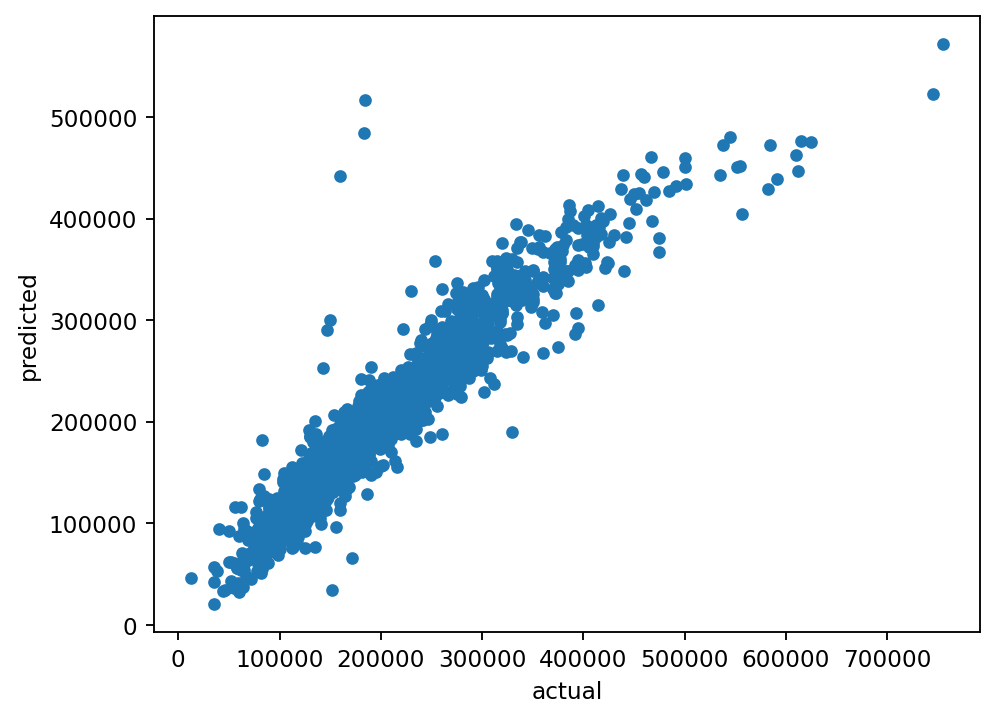

In [103]:
target.plot.scatter(x = "actual", y = "predicted")

## Practice Activity

## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

**Previously you considered selected subsets of features. Now you should try, Ridge, LASSO, and elastic net.**

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [104]:
import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df.info()

display(df["interest_rate"].describe())

display(df.isna().sum().sort_values(ascending=False).head(10))

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 56 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Unnamed: 0                        10000 non-null  int64  
 1   emp_title                         9167 non-null   str    
 2   emp_length                        9183 non-null   float64
 3   state                             10000 non-null  str    
 4   homeownership                     10000 non-null  str    
 5   annual_income                     10000 non-null  float64
 6   verified_income                   10000 non-null  str    
 7   debt_to_income                    9976 non-null   float64
 8   annual_income_joint               1495 non-null   float64
 9   verification_income_joint         1455 non-null   str    
 10  debt_to_income_joint              1495 non-null   float64
 11  delinq_2y                         10000 non-null  int64  
 12  months_since_las

count    10000.000000
mean        12.427524
std          5.001105
min          5.310000
25%          9.430000
50%         11.980000
75%         15.050000
max         30.940000
Name: interest_rate, dtype: float64

verification_income_joint           8545
annual_income_joint                 8505
debt_to_income_joint                8505
months_since_90d_late               7715
months_since_last_delinq            5658
months_since_last_credit_inquiry    1271
emp_title                            833
emp_length                           817
num_accounts_120d_past_due           318
debt_to_income                        24
dtype: int64

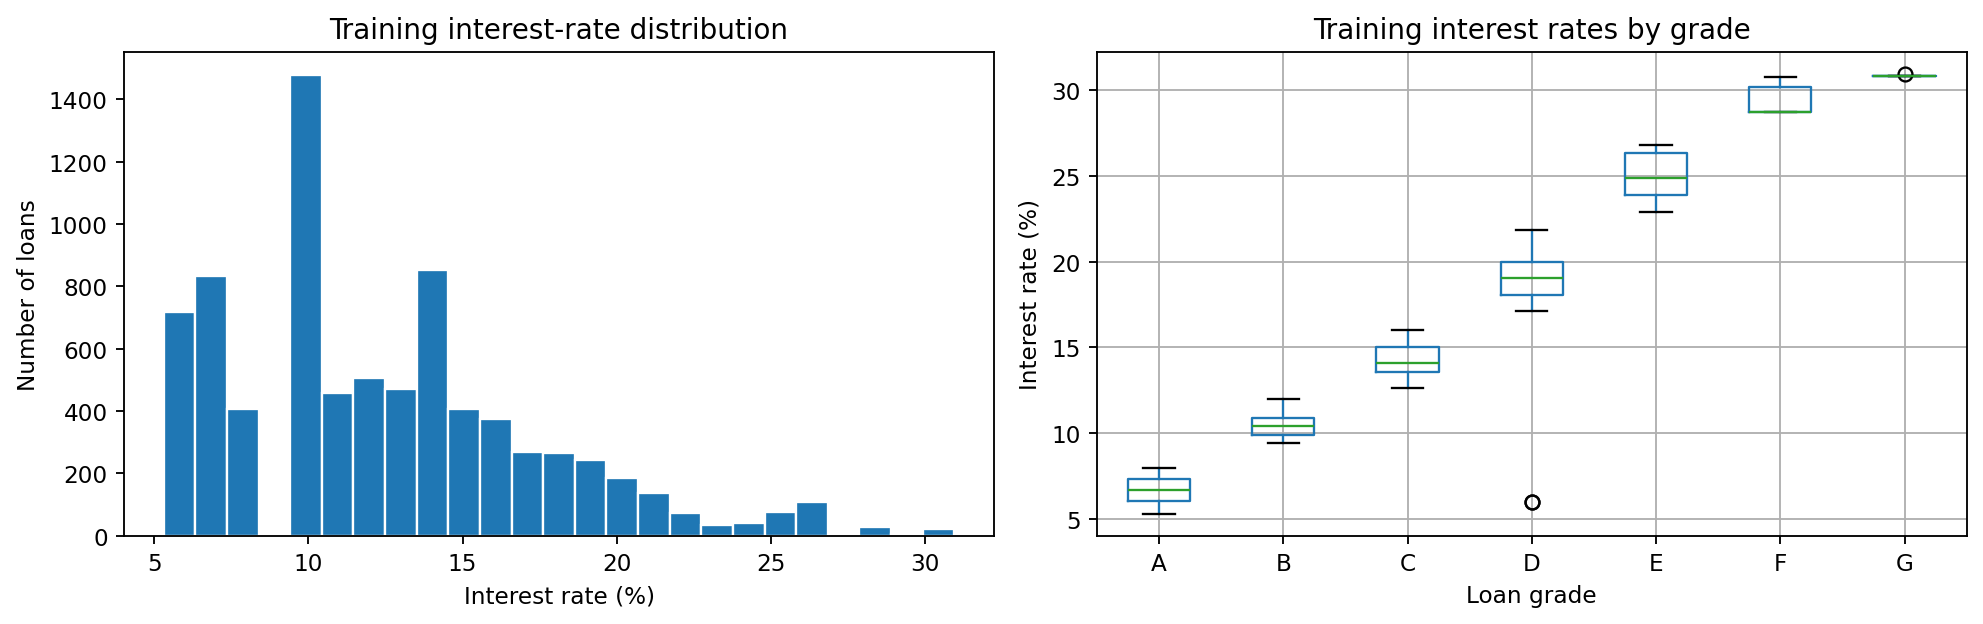

In [105]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

loans_train, loans_test = train_test_split(
    df, test_size=0.2, random_state=5544
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(loans_train["interest_rate"], bins=25, edgecolor="white")
axes[0].set_title("Training interest-rate distribution")
axes[0].set_xlabel("Interest rate (%)")
axes[0].set_ylabel("Number of loans")

loans_train.boxplot(column="interest_rate", by="grade", ax=axes[1])
axes[1].set_title("Training interest rates by grade")
axes[1].set_xlabel("Loan grade")
axes[1].set_ylabel("Interest rate (%)")

fig.suptitle("")
plt.tight_layout()
plt.show()

**Answer:** The data contain 10000 loans that were actually issued, rather than all loan applications. Interest rates have no missing values, with an overall mean of about 12.43% and a median of 11.98%. The training histogram is right-skewed, and interest rates generally increase from grade A to grade G. Credit ratings may therefore be useful predictors if they are available when making predictions. Several predictors have missing values and will need preprocessing. We reserved 20% of the observations for final testing and will use only the training set for model tuning.

In [106]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold

excluded_columns = [
    "interest_rate", "Unnamed: 0", "emp_title",
    "verification_income_joint", "installment", "issue_month",
    "loan_status", "initial_listing_status", "disbursement_method",
    "balance", "paid_total", "paid_principal",
    "paid_interest", "paid_late_fees"
]

X_train = loans_train.drop(columns=excluded_columns)
y_train = loans_train["interest_rate"]

X_test = loans_test.drop(columns=excluded_columns)
y_test = loans_test["interest_rate"]

numeric_loans = X_train.select_dtypes(include="number").columns
categorical_loans = X_train.select_dtypes(exclude="number").columns

numeric_preprocessing = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("standardize", StandardScaler())
])

loan_preprocessing = ColumnTransformer([
    ("numeric", numeric_preprocessing, numeric_loans),
    ("categorical", OneHotEncoder(
        handle_unknown="ignore", sparse_output=False
    ), categorical_loans)
])

loan_folds = KFold(n_splits=5, shuffle=True, random_state=5544)

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Numerical predictors:", len(numeric_loans))
print("Categorical predictors:", len(categorical_loans))

Training data: (8000, 42)
Test data: (2000, 42)
Numerical predictors: 35
Categorical predictors: 7


In [107]:
from sklearn.model_selection import GridSearchCV

ridge_loan_pipeline = Pipeline([
    ("preprocessing", loan_preprocessing),
    ("ridge", Ridge())
])

ridge_loan_grid = GridSearchCV(
    ridge_loan_pipeline,
    param_grid={"ridge__alpha": np.logspace(-4, 3, 8)},
    cv=loan_folds,
    scoring="neg_root_mean_squared_error"
)

ridge_loan_grid.fit(X_train, y_train)

ridge_loan_results = pd.DataFrame({
    "alpha": ridge_loan_grid.cv_results_["param_ridge__alpha"],
    "Mean CV RMSE": -ridge_loan_grid.cv_results_["mean_test_score"]
})

display(ridge_loan_results)
print("Best parameters:", ridge_loan_grid.best_params_)
print("Best mean CV RMSE:", -ridge_loan_grid.best_score_)

,alpha,Mean CV RMSE
0,0.0001,0.165101
1,0.0010,0.165101
2,0.0100,0.165107
3,0.1000,0.165277
4,1.0000,0.175551
5,10.0000,0.360979
6,100.0000,1.127131
7,1000.0000,2.673781


Best parameters: {'ridge__alpha': np.float64(0.0001)}
Best mean CV RMSE: 0.16510070552257672


In [108]:
lasso_loan_pipeline = Pipeline([
    ("preprocessing", loan_preprocessing),
    ("lasso", Lasso(max_iter=300000, selection="random", random_state=5544))
])

lasso_loan_grid = GridSearchCV(
    lasso_loan_pipeline,
    param_grid={"lasso__alpha": np.logspace(-5, 0, 6)},
    cv=loan_folds,
    scoring="neg_root_mean_squared_error"
)

lasso_loan_grid.fit(X_train, y_train)

lasso_loan_results = pd.DataFrame({
    "alpha": lasso_loan_grid.cv_results_["param_lasso__alpha"],
    "Mean CV RMSE": -lasso_loan_grid.cv_results_["mean_test_score"]
})

display(lasso_loan_results)
print("Best parameters:", lasso_loan_grid.best_params_)
print("Best mean CV RMSE:", -lasso_loan_grid.best_score_)

,alpha,Mean CV RMSE
0,0.00001,0.160414
1,0.00010,0.160611
2,0.00100,0.180988
3,0.01000,0.487683
4,0.10000,1.756199
5,1.00000,4.382739


Best parameters: {'lasso__alpha': np.float64(1e-05)}
Best mean CV RMSE: 0.16041441911198004


In [109]:
elastic_loan_pipeline = Pipeline([
    ("preprocessing", loan_preprocessing),
    ("elastic_net", ElasticNet(
        max_iter=300000, selection="random", random_state=5544
    ))
])

elastic_loan_grid = GridSearchCV(
    elastic_loan_pipeline,
    param_grid={
        "elastic_net__alpha": np.logspace(-5, 0, 6),
        "elastic_net__l1_ratio": [0.2, 0.5, 0.8]
    },
    cv=loan_folds,
    scoring="neg_root_mean_squared_error"
)

elastic_loan_grid.fit(X_train, y_train)

elastic_loan_results = pd.DataFrame({
    "alpha": elastic_loan_grid.cv_results_["param_elastic_net__alpha"],
    "l1_ratio": elastic_loan_grid.cv_results_["param_elastic_net__l1_ratio"],
    "Mean CV RMSE": -elastic_loan_grid.cv_results_["mean_test_score"]
})

display(elastic_loan_results)
print("Best parameters:", elastic_loan_grid.best_params_)
print("Best mean CV RMSE:", -elastic_loan_grid.best_score_)

,alpha,l1_ratio,Mean CV RMSE
0,0.00001,0.2,0.165420
1,0.00001,0.5,0.166261
2,0.00001,0.8,0.168648
3,0.00010,0.2,0.168424
4,0.00010,0.5,0.166651
5,0.00010,0.8,0.166046
6,0.00100,0.2,0.270860
7,0.00100,0.5,0.236108
8,0.00100,0.8,0.202831
9,0.01000,0.2,0.844705


Best parameters: {'elastic_net__alpha': np.float64(1e-05), 'elastic_net__l1_ratio': 0.2}
Best mean CV RMSE: 0.16541993092882815


In [110]:
from sklearn.metrics import root_mean_squared_error

loan_searches = {
    "Ridge": ridge_loan_grid,
    "LASSO": lasso_loan_grid,
    "Elastic Net": elastic_loan_grid
}

loan_comparison = pd.Series({
    "Ridge": -ridge_loan_grid.best_score_,
    "LASSO": -lasso_loan_grid.best_score_,
    "Elastic Net": -elastic_loan_grid.best_score_
}, name="Mean CV RMSE").sort_values()

display(loan_comparison)

best_loan_name = loan_comparison.idxmin()
best_loan_model = loan_searches[best_loan_name].best_estimator_

test_predictions = best_loan_model.predict(X_test)
test_rmse = root_mean_squared_error(y_test, test_predictions)

print("Selected model:", best_loan_name)
print("Selected parameters:", loan_searches[best_loan_name].best_params_)
print("Test RMSE (percentage points):", test_rmse)

LASSO          0.160414
Ridge          0.165101
Elastic Net    0.165420
Name: Mean CV RMSE, dtype: float64

Selected model: LASSO
Selected parameters: {'lasso__alpha': np.float64(1e-05)}
Test RMSE (percentage points): 0.07976689874729218


**Answer:** We used 42 predictors covering borrower characteristics, credit history, loan terms, and credit ratings. We excluded identifiers, the free-text job title, and payment-related variables that could reveal the interest rate. Numerical missing values were filled with training medians, with missing-value indicators added. Numerical predictors were standardized and categorical predictors were one-hot encoded within each model pipeline.

We compared Ridge, LASSO, and Elastic Net using the same five-fold cross-validation splits on 8000 training observations. GridSearchCV tuned alpha on a logarithmic scale for all three models and also tuned l1_ratio for Elastic Net. Their best mean CV RMSE values were 0.16510, 0.16041, and 0.16542 percentage points, respectively. We selected LASSO with alpha equal to 0.00001 because it had the lowest mean CV RMSE among the configurations tried.

The selected model achieved an RMSE of 0.07977 percentage points on the 2000 held-out test observations. The test set was not used for tuning or model selection. These results assume that grade and sub_grade are available when predicting and apply to issued loans, rather than all loan applications.